# NIDS — CIC-IDS2017 Hyperparameter Tuning
Gói dữ liệu commit dfb8446. Cố định split; chọn bằng validation F1 (weighted). Không dùng test để huấn luyện/chọn cấu hình. Ba trial đầu thử weighting, ba trial tiếp theo thay đổi một tham số. Full train có chi phí GPU lớn; chạy từng trial và lưu output thường xuyên.

In [41]:
import sys
import torch
import numpy as np
import pandas as pd
import sklearn
import pyarrow
import xgboost
import lightgbm

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyArrow:", pyarrow.__version__)
print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)

print("\nCUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())

assert torch.cuda.is_available(), "GPU is not enabled"

for i in range(torch.cuda.device_count()):
    gpu = torch.cuda.get_device_properties(i)
    print(f"\nGPU {i}: {gpu.name}")
    print("VRAM GiB:", round(gpu.total_memory / 1024**3, 2))

print("\nGPU ENVIRONMENT READY")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
NumPy: 2.1.3
Pandas: 2.3.3
Scikit-learn: 1.6.1
PyArrow: 23.0.1
XGBoost: 3.4.1
LightGBM: 4.6.0

CUDA available: True
CUDA version: 13.0
GPU count: 2

GPU 0: Tesla T4
VRAM GiB: 14.56

GPU 1: Tesla T4
VRAM GiB: 14.56

GPU ENVIRONMENT READY


In [42]:
from pathlib import Path
from zipfile import ZipFile
import shutil
import os

INPUT = Path("/kaggle/input")
ROOT = Path("/kaggle/working/NIDS")

ROOT.mkdir(parents=True, exist_ok=True)

manifests = list(INPUT.rglob("kaggle_manifest.json"))

if manifests:

    source = manifests[0].parent

    print("Dataset source:", source)

    shutil.copytree(
        source,
        ROOT,
        dirs_exist_ok=True
    )

else:

    archives = list(
        INPUT.rglob("NIDS_Kaggle_Training.zip")
    )

    assert archives, "Training package not found"

    with ZipFile(archives[0]) as z:
        z.extractall(ROOT)

os.chdir(ROOT)

os.environ["PYTHONPATH"] = str(ROOT / "src")

assert (ROOT / "src/nids/final_cnn.py").exists()
assert (ROOT / "kaggle_manifest.json").exists()

print("Project root:", Path.cwd())

print("\nKAGGLE PROJECT READY")

Dataset source: /kaggle/input/datasets/chienvoo/nids-kaggle-training
Project root: /kaggle/working/NIDS

KAGGLE PROJECT READY


In [43]:
import hashlib
import json

manifest = json.loads(
    (ROOT / "kaggle_manifest.json").read_text(
        encoding="utf-8"
    )
)

print("Git commit:", manifest["git_commit"])

for relative, expected in manifest["sha256"].items():

    path = ROOT / relative

    assert path.exists(), f"Missing file: {relative}"

    h = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1048576), b""
        ):
            h.update(block)

    assert h.hexdigest() == expected, relative

    print("PASS:", relative)

print("\nKAGGLE DATA INTEGRITY PASSED")

Git commit: dfb84460072a0bcaeed01d9eec0e1ac0dd371531
PASS: data/processed/final/cic/train.parquet
PASS: data/processed/final/cic/validation.parquet
PASS: data/processed/final/cic/test.parquet
PASS: data/processed/final/cic/manifest.json
PASS: data/processed/final/cic/split_indices.npz
PASS: data/processed/final/ctu/train.parquet
PASS: data/processed/final/ctu/validation.parquet
PASS: data/processed/final/ctu/test.parquet
PASS: data/processed/final/ctu/manifest.json
PASS: data/processed/final/ctu/split_indices.npz

KAGGLE DATA INTEGRITY PASSED


In [44]:
subprocess_check = __import__("subprocess")
subprocess_check.run([sys.executable, "-m", "nids.final_cnn", "--help"], cwd=ROOT, check=True)

usage: final_cnn.py [-h] [--dataset {cic,ctu,both}]
                    [--variants {cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} [{cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} ...]]
                    [--smoke] [--epochs EPOCHS] [--batch-size BATCH_SIZE]
                    [--width WIDTH] [--lr LR] [--dropout DROPOUT]
                    [--patience PATIENCE] [--seed SEED]
                    [--device {auto,cpu,cuda}]
                    [--class-weight {auto,none,sqrt,balanced}] [--amp]
                    [--tune-only] [--run-id RUN_ID]

options:
  -h, --help            show this help message and exit
  --dataset {cic,ctu,both}
  --variants {cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} [{cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} ...]
  --smoke
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --width WIDTH
  --lr LR
  --dropout DROPOUT
  --patience PATIENCE
  --seed SEED
  --device {auto,cpu,cuda}
  --class-weight {auto,none,sqrt,balanced}
  --amp
  --tune-only
  --run-id RUN_ID


CompletedProcess(args=['/usr/bin/python3', '-m', 'nids.final_cnn', '--help'], returncode=0)

In [45]:
subprocess_check.run([sys.executable, "-m", "pytest", "-q", "tests/test_final_pipeline.py", "tests/test_final_cnn.py", "tests/test_final_tuning.py"], cwd=ROOT, check=True)

.................                                                        [100%]
=============================== warnings summary ===============================
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
    prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))

../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
  /usr/local/l

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q', 'tests/test_final_pipeline.py', 'tests/test_final_cnn.py', 'tests/test_final_tuning.py'], returncode=0)

In [49]:
import subprocess, sys, os, json, shutil
import pandas as pd
import numpy as np
from pathlib import Path
assert manifest["git_commit"].startswith("dfb8446")
DATA = ROOT / "data/processed/final/cic"
META = json.loads((DATA / "manifest.json").read_text())
assert META["split_sizes"] == {"train":1764676,"validation":378145,"test":378145}
RUNS = ROOT / "outputs/final/tuning/cic"
REPORT = ROOT / "reports/final/cic_tuning"
RUNS.mkdir(parents=True, exist_ok=True)
REPORT.mkdir(parents=True, exist_ok=True)
TRIALS = [
    ("T01",32,.001,.1,"none"),
    ("T02",32,.001,.1,"sqrt"),
    ("T03",32,.001,.1,"balanced"),
    ("T04",64,.001,.1,"sqrt"),
    ("T05",32,.0005,.1,"sqrt"),
    ("T06",32,.001,.2,"sqrt"),
]
EPOCHS=10
BATCH=512
SEED=42
PATIENCE=3
# Run one or more trials per session; change this list without changing the design.
ACTIVE = ["T04", "T05", "T06"]
PLAN=dict(trials=[list(t) for t in TRIALS],epochs=EPOCHS,batch_size=BATCH,seed=SEED,patience=PATIENCE,commit=manifest["git_commit"],split_sha256=META["split_sha256"])
p=RUNS/"plan.json"
if p.exists(): assert json.loads(p.read_text())==PLAN
else: p.write_text(json.dumps(PLAN,indent=2))
print(PLAN)


{'trials': [['T01', 32, 0.001, 0.1, 'none'], ['T02', 32, 0.001, 0.1, 'sqrt'], ['T03', 32, 0.001, 0.1, 'balanced'], ['T04', 64, 0.001, 0.1, 'sqrt'], ['T05', 32, 0.0005, 0.1, 'sqrt'], ['T06', 32, 0.001, 0.2, 'sqrt']], 'epochs': 10, 'batch_size': 512, 'seed': 42, 'patience': 3, 'commit': 'dfb84460072a0bcaeed01d9eec0e1ac0dd371531', 'split_sha256': {'train': '597d8ec35dcebb218af51dc15302757fb81c8127a062b972903eb242ed84615e', 'validation': '0786e13f3cada384fe61077caed781ff30e262ab74bc16c46ac7df2c8444c89c', 'test': '3eacdb2b228737ecd8cc57f1c83acd7b5eda62ef73aa857cff462ac51e2e83c9'}}


In [50]:
def validate_trial(t):
    tid,width,lr,dropout,weight=t
    folder=RUNS/tid
    d=json.loads((folder/"tuning_metrics.json").read_text())
    a=d["arguments"]
    assert d["dataset"]=="cic" and d["profile"]=="tuning" and d["device"]=="cuda"
    assert d["split_sizes"]=={"train":1764676,"validation":378145}
    assert d["split_sha256"]==META["split_sha256"] and d["features"]==META["features"]
    expected=dict(width=width,lr=lr,dropout=dropout,class_weight=weight,epochs=EPOCHS,batch_size=BATCH,seed=SEED,patience=PATIENCE,amp=True,tune_only=True,smoke=False,run_id=tid)
    assert all(a[k]==v for k,v in expected.items())
    assert set(d["models"])=={"cnn_se_mhsa"}
    m=d["models"]["cnn_se_mhsa"]
    assert "test" not in m
    assert (folder/"cnn_se_mhsa_best_state.pt").is_file()
    h=pd.read_csv(folder/"cnn_se_mhsa_history.csv")
    assert np.isclose(h.validation_f1.max(),m["validation"]["f1_score"],atol=1e-7)
    return m
for t in TRIALS:
    tid,width,lr,dropout,weight=t
    if tid not in ACTIVE: continue
    folder=RUNS/tid
    if (folder/"tuning_metrics.json").exists():
        validate_trial(t); print("Already complete:",tid); continue
    if folder.exists(): raise RuntimeError(f"Archive incomplete trial {folder} before retrying")
    cmd=[sys.executable,"-u","-m","nids.final_cnn","--dataset","cic","--variants","cnn_se_mhsa","--epochs",str(EPOCHS),"--batch-size",str(BATCH),"--width",str(width),"--lr",str(lr),"--dropout",str(dropout),"--class-weight",weight,"--patience",str(PATIENCE),"--seed",str(SEED),"--device","cuda","--amp","--tune-only","--run-id",tid]
    subprocess.run(cmd,cwd=ROOT,env={**os.environ,"PYTHONPATH":str(ROOT/"src")},check=True)
    validate_trial(t)
    print("COMPLETED",tid)


Device: cuda


/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


cic/cnn_se_mhsa Epoch 1/10 Loss=0.17538 ValF1=0.958751
cic/cnn_se_mhsa Epoch 2/10 Loss=0.11276 ValF1=0.967733
cic/cnn_se_mhsa Epoch 3/10 Loss=0.10450 ValF1=0.969314
cic/cnn_se_mhsa Epoch 4/10 Loss=0.09946 ValF1=0.969445
cic/cnn_se_mhsa Epoch 5/10 Loss=0.09346 ValF1=0.976528
cic/cnn_se_mhsa Epoch 6/10 Loss=0.08831 ValF1=0.977786
cic/cnn_se_mhsa Epoch 7/10 Loss=0.08363 ValF1=0.977065
cic/cnn_se_mhsa Epoch 8/10 Loss=0.08215 ValF1=0.978517
cic/cnn_se_mhsa Epoch 9/10 Loss=0.08182 ValF1=0.975473
cic/cnn_se_mhsa Epoch 10/10 Loss=0.08202 ValF1=0.973093
      Model  Validation Accuracy  Validation Precision  Validation Recall  Validation F1  Best epoch  Training seconds
cnn_se_mhsa             0.975335              0.983888           0.975335       0.978517           8        851.864563
Saved: /kaggle/working/NIDS/outputs/final/tuning/cic/T04
COMPLETED T04
Device: cuda


/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


cic/cnn_se_mhsa Epoch 1/10 Loss=0.21627 ValF1=0.963705
cic/cnn_se_mhsa Epoch 2/10 Loss=0.11529 ValF1=0.969128
cic/cnn_se_mhsa Epoch 3/10 Loss=0.10320 ValF1=0.971132
cic/cnn_se_mhsa Epoch 4/10 Loss=0.09635 ValF1=0.970552
cic/cnn_se_mhsa Epoch 5/10 Loss=0.09207 ValF1=0.974066
cic/cnn_se_mhsa Epoch 6/10 Loss=0.08840 ValF1=0.978248
cic/cnn_se_mhsa Epoch 7/10 Loss=0.08202 ValF1=0.980414
cic/cnn_se_mhsa Epoch 8/10 Loss=0.08116 ValF1=0.980235
cic/cnn_se_mhsa Epoch 9/10 Loss=0.08018 ValF1=0.980270
cic/cnn_se_mhsa Epoch 10/10 Loss=0.07913 ValF1=0.980003
Early stopping
      Model  Validation Accuracy  Validation Precision  Validation Recall  Validation F1  Best epoch  Training seconds
cnn_se_mhsa             0.977675              0.985445           0.977675       0.980414           7        595.694178
Saved: /kaggle/working/NIDS/outputs/final/tuning/cic/T05
COMPLETED T05
Device: cuda


/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


cic/cnn_se_mhsa Epoch 1/10 Loss=0.21578 ValF1=0.959494
cic/cnn_se_mhsa Epoch 2/10 Loss=0.13038 ValF1=0.969404
cic/cnn_se_mhsa Epoch 3/10 Loss=0.11716 ValF1=0.970564
cic/cnn_se_mhsa Epoch 4/10 Loss=0.11031 ValF1=0.970681
cic/cnn_se_mhsa Epoch 5/10 Loss=0.10787 ValF1=0.970177
cic/cnn_se_mhsa Epoch 6/10 Loss=0.10477 ValF1=0.970518
cic/cnn_se_mhsa Epoch 7/10 Loss=0.09949 ValF1=0.976126
cic/cnn_se_mhsa Epoch 8/10 Loss=0.09569 ValF1=0.979025
cic/cnn_se_mhsa Epoch 9/10 Loss=0.08870 ValF1=0.981281
cic/cnn_se_mhsa Epoch 10/10 Loss=0.09148 ValF1=0.977766
      Model  Validation Accuracy  Validation Precision  Validation Recall  Validation F1  Best epoch  Training seconds
cnn_se_mhsa             0.979146              0.985554           0.979146       0.981281           9        596.299636
Saved: /kaggle/working/NIDS/outputs/final/tuning/cic/T06
COMPLETED T06


,Trial,Width,LR,Dropout,Weight,Accuracy,Precision,Recall,F1,BestEpoch,TrainingSeconds
0,T01,32,0.0010,0.1,none,0.987312,0.987154,0.987312,0.987051,4,416.628660
5,T06,32,0.0010,0.2,sqrt,0.979146,0.985554,0.979146,0.981281,9,596.299636
1,T02,32,0.0010,0.1,sqrt,0.977887,0.985393,0.977887,0.980537,9,595.667762
4,T05,32,0.0005,0.1,sqrt,0.977675,0.985445,0.977675,0.980414,7,595.694178
3,T04,64,0.0010,0.1,sqrt,0.975335,0.983888,0.975335,0.978517,8,851.864563
2,T03,32,0.0010,0.1,balanced,0.926063,0.970591,0.926063,0.944078,9,599.705199


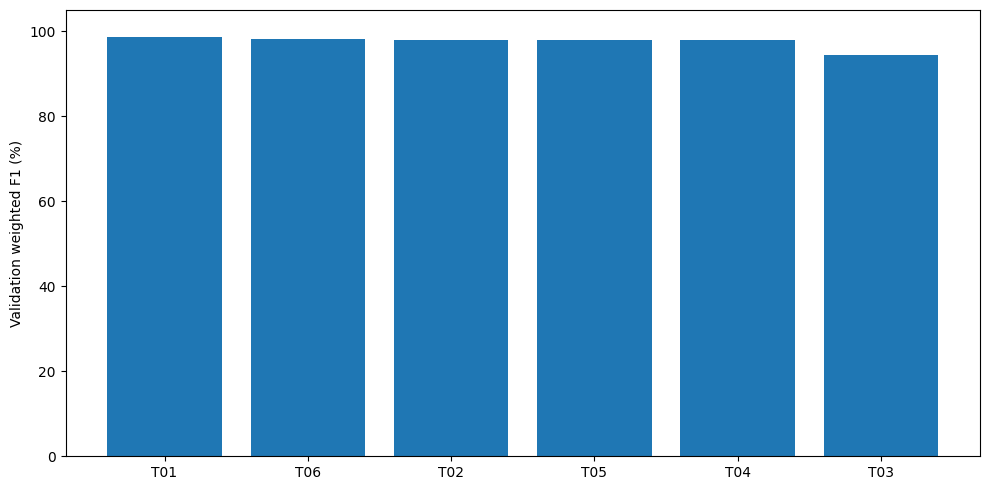

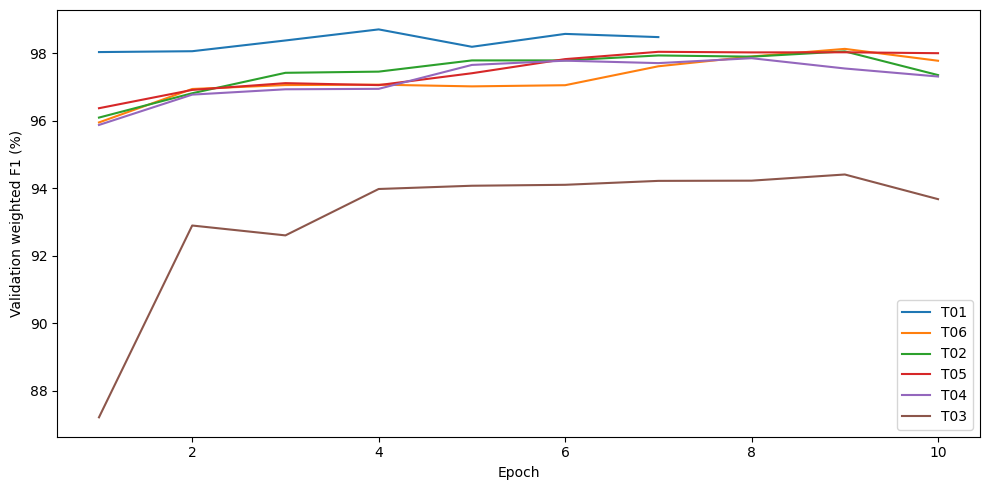

/kaggle/working/NIDS_CIC_Tuning_Results.zip
/kaggle/working/NIDS_CIC_Tuning_Reports.zip
ALL CIC TUNING TRIALS COMPLETED


In [53]:
import matplotlib.pyplot as plt
rows=[]
for t in TRIALS:
    tid,width,lr,dropout,weight=t
    if not (RUNS/tid/"tuning_metrics.json").exists(): continue
    m=validate_trial(t)
    v=m["validation"]
    rows.append(dict(Trial=tid,Width=width,LR=lr,Dropout=dropout,Weight=weight,Accuracy=v["accuracy"],Precision=v["precision"],Recall=v["recall"],F1=v["f1_score"],BestEpoch=m["best_epoch"],TrainingSeconds=m["training_seconds"]))
assert rows,"No completed trials"
summary=pd.DataFrame(rows).sort_values(["F1","Trial"],ascending=[False,True])
summary.to_csv(REPORT/"tuning_summary.csv",index=False)
display(summary)
complete=len(rows)==len(TRIALS)
if complete:
    (REPORT/"best_config.json").write_text(json.dumps(summary.iloc[0].to_dict(),indent=2))
else:
    (REPORT/"best_config.json").unlink(missing_ok=True)
fig,ax=plt.subplots(figsize=(10,5))
ax.bar(summary.Trial,summary.F1*100); ax.set(ylabel="Validation weighted F1 (%)",ylim=(0,105))
fig.tight_layout(); fig.savefig(REPORT/"01_tuning_f1.png",dpi=300); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(10,5))
for tid in summary.Trial:
    h=pd.read_csv(RUNS/tid/"cnn_se_mhsa_history.csv")
    ax.plot(h.epoch,h.validation_f1*100,label=tid)
ax.set(xlabel="Epoch",ylabel="Validation weighted F1 (%)"); ax.legend()
fig.tight_layout(); fig.savefig(REPORT/"02_learning_curves.png",dpi=300); plt.show(); plt.close(fig)
lines=["# CIC-IDS2017 — Hyperparameter Tuning","",f"Hoàn thành {len(rows)}/{len(TRIALS)} trial. Train 1.764.676; validation 378.145. F1 weighted; không đánh giá test trong tuning.","","| Trial | Width | LR | Dropout | Weight | Validation F1 |","|---|---:|---:|---:|---|---:|"]
for _,r in summary.iterrows():
    lines.append(f"| {r.Trial} | {r.Width} | {r.LR} | {r.Dropout} | {r.Weight} | {r.F1*100:.4f}% |")
lines+=["", "Cấu hình được chọn: "+str(summary.iloc[0].Trial) if complete else "Chưa chọn cấu hình cuối vì chưa đủ trial.","","![F1](01_tuning_f1.png)","","![Learning curves](02_learning_curves.png)","","Giới hạn: một seed, ngân sách 10 epoch; chia tập ngẫu nhiên nội bộ, lớp hiếm cần xem báo cáo từng lớp."]
(REPORT/"07_CIC_HYPERPARAMETER_TUNING.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
from zipfile import ZipFile,ZIP_DEFLATED
for name,folder in [("NIDS_CIC_Tuning_Results",RUNS),("NIDS_CIC_Tuning_Reports",REPORT)]:
    dest=Path("/kaggle/working")/(name+".zip")
    with ZipFile(dest,"w",ZIP_DEFLATED) as z:
        for p in sorted(folder.rglob("*")):
            if p.is_file(): z.write(p,p.relative_to(ROOT))
    with ZipFile(dest) as z: assert z.testzip() is None
    print(dest)
print("ALL CIC TUNING TRIALS COMPLETED" if complete else "PARTIAL CIC TUNING ARTIFACTS SAVED")
